Промежуточные выборы в Конгресс (*midterms*) проходят за 2 года до президентских и показывают настроение страны. 

MIT Election Lab, *U.S. House 1976–2024* ((https://doi.org/10.7910/DVN/IG0UN2)).

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DEM, GRAY = "#2a78d6", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
})

HOUSE = Path("../data/raw/1976-2024-house.tab")
assert HOUSE.exists(), " 1976-2024-house.tab https://doi.org/10.7910/DVN/IG0UN2 "

house = pd.read_csv(HOUSE, low_memory=False)  
print(house.shape)
house.head(3)

(33805, 20)


,year,state,state_po,state_fips,state_cen,state_ic,office,district,stage,runoff,special,candidate,party,writein,mode,candidatevotes,totalvotes,unofficial,version,fusion_ticket
0,1976,ALABAMA,AL,1,63,41,US HOUSE,1,GEN,False,False,BILL DAVENPORT,DEMOCRAT,False,TOTAL,58906,157170,False,20250910,False
1,1976,ALABAMA,AL,1,63,41,US HOUSE,1,GEN,False,False,JACK EDWARDS,REPUBLICAN,False,TOTAL,98257,157170,False,20250910,False
2,1976,ALABAMA,AL,1,63,41,US HOUSE,1,GEN,False,False,WRITEIN,NaN,True,TOTAL,7,157170,False,20250910,False


Выборы каждые 2 года, 435 округов.

1. Оставляем только основные выборы в ноябре: без праймериз (`stage = PRI`), досрочных (`special`) и вторых туров (`runoff`).
2. Разные названия партий
3. Один кандидат — несколько партий. Суммируем голоса по кандидату.

In [ ]:
house = house[(house.stage == "GEN") & ~house.special & (house.runoff != True)]

DEM_LABELS = ["DEMOCRAT", "DEMOCRATIC", "DEMOCRATIC-FARM-LABOR", "DEMOCRATIC-FARMER-LABOR",
              "DEMOCRATIC-NONPARTISAN LEAGUE", "DEMOCRATIC-NPL"]
REP_LABELS = ["REPUBLICAN", "INDEPENDENT-REPUBLICAN"]
house["side"] = np.select([house.party.isin(DEM_LABELS), house.party.isin(REP_LABELS)], ["D", "R"], "")
house["votes"] = house.candidatevotes.clip(lower=0)  # во Флориде встречается −1

# кандидат → его сторона и все его голоса (со всех партийных строк)
candidates = (house.groupby(["year", "state_po", "district", "candidate"])
              .agg(votes=("votes", "sum"), side=("side", "max")).reset_index())
districts = candidates.pivot_table(index=["year", "state_po", "district"], columns="side",
                                   values="votes", aggfunc="sum", fill_value=0).reset_index()
districts[["year", "state_po", "district", "D", "R"]].head()

side,year,state_po,district,D,R
0,1976,AK,0,34194,83722
1,1976,AL,1,58906,98257
2,1976,AL,2,66288,90069
3,1976,AL,3,106935,0
4,1976,AL,4,141490,34531



Во многих округах одна из партий вообще не выставляет кандидата. Считаем долю демократов по округам, где были и D, и R.

In [ ]:
contested = districts[(districts.D > 0) & (districts.R > 0)]
print("доля округов с кандидатами от обеих партий:")
print((contested.groupby("year").size() / districts.groupby("year").size()).round(2).to_dict())

national = contested.groupby("year")[["D", "R"]].sum()
national_share = national.D / (national.D + national.R)  # доля демократов в Палату, по стране

by_state = contested.groupby(["year", "state_po"])[["D", "R"]].sum().reset_index()
by_state["house_dem"] = by_state.D / (by_state.D + by_state.R)
by_state = by_state.rename(columns={"state_po": "state"})[["year", "state", "house_dem"]]
print("\nдоля демократов в Палату по стране:")
print(national_share.round(3).to_dict())

доля округов с кандидатами от обеих партий:
{1976: 0.88, 1978: 0.84, 1980: 0.89, 1982: 0.87, 1984: 0.84, 1986: 0.83, 1988: 0.81, 1990: 0.8, 1992: 0.92, 1994: 0.88, 1996: 0.95, 1998: 0.78, 2000: 0.85, 2002: 0.81, 2004: 0.85, 2006: 0.87, 2008: 0.87, 2010: 0.93, 2012: 0.9, 2014: 0.82, 2016: 0.86, 2018: 0.91, 2020: 0.94, 2022: 0.93, 2024: 0.91}

доля демократов в Палату по стране:
{1976: 0.548, 1978: 0.53, 1980: 0.497, 1982: 0.538, 1984: 0.497, 1986: 0.529, 1988: 0.514, 1990: 0.534, 1992: 0.529, 1994: 0.483, 1996: 0.5, 1998: 0.508, 2000: 0.501, 2002: 0.483, 2004: 0.496, 2006: 0.521, 2008: 0.538, 2010: 0.479, 2012: 0.511, 2014: 0.467, 2016: 0.488, 2018: 0.519, 2020: 0.505, 2022: 0.491, 2024: 0.489}


1994 — «республиканская революция» (демократы 48%), 2010 — волна «Чайной партии» (48%), 2018 — демократическая волна при Трампе (52%)


In [ ]:
results = pd.read_csv("../data/processed/state_results.csv")
features = pd.read_csv("../data/processed/state_features.csv")  # из ноутбука 02

elections = features.groupby("year").incumbent.first().to_frame()
sign = np.where(elections.incumbent == "D", 1, -1)
# для выборов президента в год Y: midterms были в Y−2, прошлые выборы в Палату — в Y−4
elections["midterm_swing"] = sign * (elections.index.map(lambda y: national_share.get(y - 2))
                                     - elections.index.map(lambda y: national_share.get(y - 4)))

pres = results.groupby("year")[["dem_votes", "rep_votes"]].sum()
pres_dem = pres.dem_votes / (pres.dem_votes + pres.rep_votes)
elections["inc_pres_share"] = np.where(sign == 1, pres_dem.reindex(elections.index),
                                       1 - pres_dem.reindex(elections.index))
elections = elections.dropna()
elections.round(3)

,incumbent,midterm_swing,inc_pres_share
year,,,
1980,D,-0.018,0.447
1984,R,-0.041,0.592
1988,R,-0.032,0.539
1992,R,-0.020,0.465
1996,D,-0.045,0.547
2000,D,0.008,0.503
2004,R,0.018,0.512
2008,R,-0.025,0.463
2012,D,-0.060,0.520


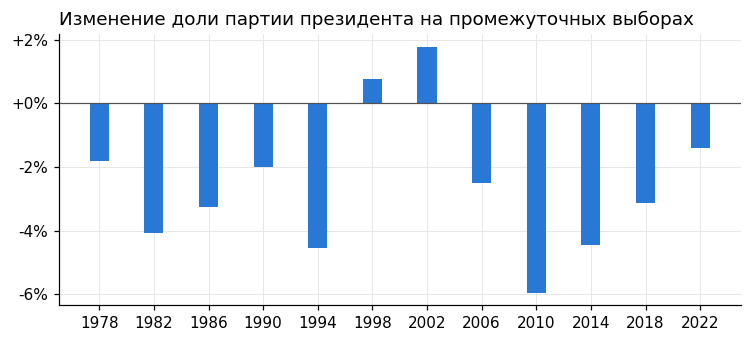

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.2))
midterm_years = elections.index - 2
ax.bar(midterm_years, elections.midterm_swing, width=1.4, color=DEM)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xticks(midterm_years)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_title("Изменение доли партии президента на промежуточных выборах", loc="left")
plt.show()

Партия президента проседает почти на каждых промежуточных выборах. Исключения — 1998 (импичмент Клинтона сыграл против республиканцев) и 2002 (после 11 сентября). 

Предсказывают ли midterms следующие президентские выборы?

Каждая точка — одни президентские выборы (подпись — их год). По горизонтали — просадка партии президента на midterms за 2 года до них, по вертикали — её доля голосов на самих президентских выборах.

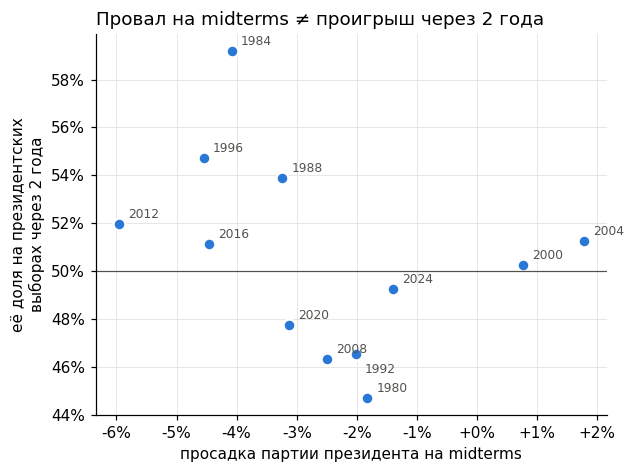

корреляция: -0.34


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(elections.midterm_swing, elections.inc_pres_share, s=60, color=DEM,
           edgecolors="white", linewidths=1.5, zorder=2)
for year, row in elections.iterrows():
    offset = (6, -12) if year == 1992 else (6, 4)  # чтобы подписи 1992 и 2008 не слиплись
    ax.annotate(str(year), (row.midterm_swing, row.inc_pres_share), xytext=offset,
                textcoords="offset points", fontsize=8, color="#52514e")
ax.axhline(0.5, color="#52514e", lw=0.8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set(xlabel="просадка партии президента на midterms",
       ylabel="её доля на президентских\nвыборах через 2 года")
ax.set_title("Провал на midterms ≠ проигрыш через 2 года", loc="left")
plt.show()
print("корреляция:", round(elections.midterm_swing.corr(elections.inc_pres_share), 2))

Корреляция −0,34 на 12 точках 
Самый сильный провал — midterms 2010 (−6%), один из самых сильных — 1994 (−4,5%), но через 2 года президент-демократ оба раза переизбрался (2012 и 1996). Избиратели против партии президента на промежуточных выборах почти всегда, а через 2 года голосуют уже за конкретных кандидатов.

* `nat_midterm_swing` — просадка партии президента **по стране**;
* `state_midterm_swing` — в конкретном штате. Если в штате на midterms не было ни одного округа с кандидатами от обеих партий, берём значение по стране.


In [ ]:
mid = by_state.assign(year=by_state.year + 2).rename(columns={"house_dem": "mid"})  # midterms → год Y
pre = by_state.assign(year=by_state.year + 4).rename(columns={"house_dem": "pre"})  # 4 года назад → год Y
data = (features.dropna(subset=["inc_win"])
        .merge(mid, on=["year", "state"], how="left")
        .merge(pre, on=["year", "state"], how="left")
        .merge(elections[["midterm_swing"]], left_on="year", right_index=True))
data["inc_win"] = data.inc_win.astype(int)

sign = np.where(data.incumbent == "D", 1, -1)
data["nat_midterm_swing"] = data.midterm_swing
data["state_midterm_swing"] = (sign * (data.mid - data.pre)).fillna(data.nat_midterm_swing)
data[["year", "state", "nat_midterm_swing", "state_midterm_swing"]].query("state == 'PA'").round(3)

,year,state,nat_midterm_swing,state_midterm_swing
456,1980,PA,-0.018,-0.052
457,1984,PA,-0.041,-0.030
458,1988,PA,-0.032,0.054
459,1992,PA,-0.020,-0.041
460,1996,PA,-0.045,0.012
461,2000,PA,0.008,0.009
462,2004,PA,0.018,0.003
463,2008,PA,-0.025,-0.037
464,2012,PA,-0.060,-0.081
465,2016,PA,-0.045,-0.046


In [ ]:
BASE = ["inc_prev_share", "inc_prev_lean", "inc_running", "inc_long_tenure", "inc_home_state"]
TEST_YEARS = [1996, 2000, 2004, 2008, 2012, 2016, 2020, 2024]


def backtest(model, features):
    parts = []
    for year in TEST_YEARS:
        train, test = data[data.year < year], data[data.year == year]
        fitted = clone(model).fit(train[features], train.inc_win)
        parts.append(test.assign(proba=fitted.predict_proba(test[features])[:, 1]))
    pred = pd.concat(parts)
    return pd.Series({"accuracy": accuracy_score(pred.inc_win, pred.proba > 0.5),
                      "log_loss": log_loss(pred.inc_win, pred.proba.clip(0.01, 0.99))})


models = {
    "logistic_regression": make_pipeline(StandardScaler(), LogisticRegression()),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42),
}
variants = {
    "без midterms (модель из 02)": BASE,
    "+ просадка по стране": BASE + ["nat_midterm_swing"],
    "+ просадка по штату": BASE + ["state_midterm_swing"],
}
comparison = pd.concat({
    model_name: pd.DataFrame({name: backtest(model, feats) for name, feats in variants.items()}).T
    for model_name, model in models.items()
}, axis=1)
comparison.round(3)

logistic_regression          random_forest  \
                                       accuracy log_loss      accuracy   
без midterms (модель из 02)               0.902    0.247         0.904   
+ просадка по стране                      0.799    0.557         0.850   
+ просадка по штату                       0.904    0.250         0.912   

                                      
                            log_loss  
без midterms (модель из 02)    0.265  
+ просадка по стране           0.302  
+ просадка по штату            0.266


* Просадка по стране ухудшает модель у обеих моделей: точность падает на 5–10 п.п, log loss растёт. Признак почти всегда отрицательный и при этом не связан с итогом через 2 года, а 12 выборов —  мало, чтобы модель это поняла. Она находит случайную закономерность и переобучается.
* Просадка по штату почти ничего не меняет: разница с моделью без midterms — 1–3 штата из 408, а log loss у логистической регрессии даже чуть хуже. 

